# Week 3 – Error analysis (Yohan ALLOUCHE)

On which games is the model wrong, and why? We study the **gradient boosting at T = 30** (best model of notebook 05 at T = 30, Yohan's model) on the **validation set**, with the 0.5 threshold used in the comparison table.

The probabilities come from `val_proba.parquet`, written by notebook 05: the model is not retrained here. The test set is not used.

Each validation game falls in one of four groups:
- **TP** (true positive): predicted success, real success;
- **FP** (false positive): predicted success, real failure: a false alarm;
- **FN** (false negative): predicted failure, real success: a missed success;
- **TN** (true negative): predicted failure, real failure.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from config import *

MODEL, T = "Gradient boosting", 30

proba = pd.read_parquet(PROC_DIR / "val_proba.parquet")
proba = proba[(proba["model"] == MODEL) & (proba["T"] == T)][["app_id", "proba"]]
target = pd.read_parquet(PROC_DIR / "target.parquet")
signals = pd.read_parquet(PROC_DIR / f"features_T{T}.parquet")
games = pd.read_parquet(PROC_DIR / "games_clean.parquet", columns=["app_id", "title", "price_original", "genres"])

df = proba.merge(target, on="app_id").merge(signals, on="app_id").merge(games, on="app_id")
assert (df["split"] == "val").all() and len(df) == len(proba)

df["pred"] = df["proba"] >= 0.5
df["outcome"] = np.select([df["success"] & df["pred"], ~df["success"] & df["pred"], df["success"] & ~df["pred"]],
                          ["TP", "FP", "FN"], default="TN")
df["outcome"].value_counts()

outcome
TN    1178
TP     208
FP      86
FN      27
Name: count, dtype: int64

## 1. Are the errors close to the success threshold?

A game is a success with at least 66 reviews in its first year (threshold of the train set) and at least 80% positive reviews. A game with 60 reviews or 79% of positive reviews is almost a success: errors on these games are expected. We look at the error rate by number of reviews in the first year.

In [2]:
threshold = target.loc[target["split"] == "train", "n_reviews_1y"].quantile(TOP_QUANTILE)
bins = [0, 1, threshold / 2, threshold, 2 * threshold, 5 * threshold, np.inf]
df["reviews_1y_bin"] = pd.cut(df["n_reviews_1y"], bins, right=False)
df["error"] = df["outcome"].isin(["FP", "FN"])

df.groupby("reviews_1y_bin", observed=True).agg(n_games=("app_id", "size"), error_rate=("error", "mean"),
                                                n_FP=("outcome", lambda s: (s == "FP").sum()),
                                                n_FN=("outcome", lambda s: (s == "FN").sum())).round(3)

,n_games,error_rate,n_FP,n_FN
reviews_1y_bin,,,,
"[0.0, 1.0)",324,0.000,0,0
"[1.0, 33.0)",709,0.023,16,0
"[33.0, 66.0)",129,0.318,41,0
"[66.0, 132.0)",103,0.204,6,15
"[132.0, 330.0)",87,0.230,14,6
"[330.0, inf)",147,0.102,9,6


## 2. Why the false alarms (FP)?

A false alarm can fail the target in two ways: not enough reviews in the first year (popularity), or enough reviews but less than 80% positive (satisfaction). The second case is a game that started well and was criticised later.

In [3]:
fp = df[df["outcome"] == "FP"]
print("False alarms:", len(fp))
print("  not enough reviews in the first year:", (fp["n_reviews_1y"] < threshold).sum())
print("  enough reviews but < 80% positive:   ", ((fp["n_reviews_1y"] >= threshold) & (fp["pos_ratio_1y"] < MIN_POS_RATIO)).sum())

# Positive ratio at T = 30 compared with the one after one year: did the opinion drop?
fp[["pos_ratio", "pos_ratio_1y"]].describe().round(3)

False alarms: 86
  not enough reviews in the first year: 57
  enough reviews but < 80% positive:    29


,pos_ratio,pos_ratio_1y
count,86.000,86.000
mean,0.895,0.851
std,0.088,0.102
min,0.728,0.617
25%,0.816,0.774
50%,0.910,0.858
75%,0.992,0.952
max,1.000,1.000


## 3. Why the missed successes (FN)?

Are the missed successes games that were slow to start (few reviews in the first 30 days)?

In [4]:
compare = df[df["outcome"].isin(["TP", "FN"])].groupby("outcome").agg(
    n_games=("app_id", "size"),
    median_reviews_T30=("n_reviews", "median"),
    share_no_review_T30=("has_reviews", lambda s: 1 - s.mean()),
    median_reviews_1y=("n_reviews_1y", "median"),
    median_pos_ratio_T30=("pos_ratio", "median"))
compare.round(3)

,n_games,median_reviews_T30,share_no_review_T30,median_reviews_1y,median_pos_ratio_T30
outcome,,,,,
FN,27,17.0,0.0,98.0,0.771
TP,208,115.5,0.0,349.5,0.931


## 4. Error rate by genre and by price

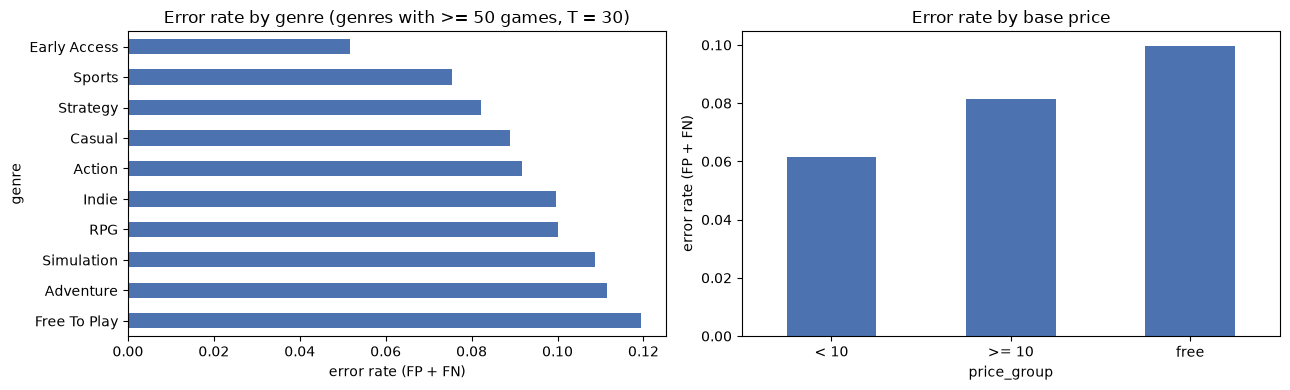

,n_games,error_rate,success_rate
price_group,,,
< 10,762,0.062,0.097
>= 10,406,0.081,0.224
free,331,0.100,0.211


In [5]:
by_genre = (df.assign(genre=df["genres"].str.split(",")).explode("genre")
              .groupby("genre").agg(n_games=("app_id", "size"), error_rate=("error", "mean"),
                                    success_rate=("success", "mean")))
by_genre = by_genre[by_genre["n_games"] >= 50].sort_values("error_rate", ascending=False)

df["price_group"] = np.select([df["price_original"] == 0, df["price_original"] < 10], ["free", "< 10"], default=">= 10")
by_price = df.groupby("price_group").agg(n_games=("app_id", "size"), error_rate=("error", "mean"),
                                         success_rate=("success", "mean"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
by_genre["error_rate"].plot.barh(ax=axes[0], color="#4C72B0")
axes[0].set(xlabel="error rate (FP + FN)", title=f"Error rate by genre (genres with >= 50 games, T = {T})")
by_price["error_rate"].plot.bar(ax=axes[1], color="#4C72B0", rot=0)
axes[1].set(ylabel="error rate (FP + FN)", title="Error rate by base price")
plt.tight_layout(); plt.savefig(ROOT / "report" / "figures" / "errors_by_group.png", dpi=150); plt.show()
by_price.round(3)

A genre with a high error rate may simply have more successes (errors are more likely where the classes are mixed): compare `error_rate` with `success_rate`. Games missing from FronkonGames have no genre and do not appear in the genre chart.

## 5. The most confident errors

The false alarms with the highest probability and the missed successes with the lowest probability: reading their titles and numbers helps to understand what the model cannot see.

In [6]:
cols = ["title", "proba", "n_reviews", "pos_ratio", "n_reviews_1y", "pos_ratio_1y", "price_original", "genres"]
print("False alarms with the highest probability:")
display(df[df["outcome"] == "FP"].sort_values("proba", ascending=False)[cols].head(10).round(3))
print("Missed successes with the lowest probability:")
display(df[df["outcome"] == "FN"].sort_values("proba")[cols].head(10).round(3))

False alarms with the highest probability:


,title,proba,n_reviews,pos_ratio,n_reviews_1y,pos_ratio_1y,price_original,genres
681,MyCompany996,0.988,100,0.840,154,0.799,9.99,"Adventure,Indie,Simulation"
1200,Magical Battle Cry,0.986,89,0.843,514,0.693,19.99,"Action,Simulation,Early Access"
837,Shenmue III,0.984,178,0.893,340,0.782,29.99,"Action,Adventure"
840,Bridge Constructor: The Walking Dead,0.984,43,0.953,65,0.954,9.99,Simulation
1024,Happy New Year Zeliria!,0.977,35,0.914,54,0.926,0.00,"Adventure,Casual,Free To Play,Indie"
1449,Paradise Lost,0.975,372,0.847,720,0.717,14.99,"Adventure,Indie"
768,The Last Show of Mr. Chardish,0.955,37,1.000,56,1.000,9.99,"Action,Adventure,Casual,Indie"
952,Love Puzzle,0.949,48,0.833,141,0.617,1.99,"Adventure,Casual,Indie,Simulation"
651,10mg :),0.947,26,1.000,29,1.000,2.99,"Action,Casual,Indie"
1057,Shokuo Shoujo,0.946,80,0.825,138,0.790,12.99,"Adventure,Casual,Indie,RPG,Simulation,Strategy"


Missed successes with the lowest probability:


,title,proba,n_reviews,pos_ratio,n_reviews_1y,pos_ratio_1y,price_original,genres
454,Solar System VR,0.002,3,0.333,69,0.870,3.99,"Adventure,Indie,Simulation"
1210,Royale Island Showdown,0.011,17,0.647,69,0.855,0.00,"Action,Free To Play,Indie"
267,Hello Neighbor 2 Alpha 1.5,0.019,234,0.654,1551,0.831,0.00,"Adventure,Indie,Strategy"
70,Touhou Seirensen ~ Undefined Fantastic Object.,0.052,14,1.000,68,0.971,14.99,"Action,Indie"
169,Anno 1404 - History Edition,0.055,13,0.615,294,0.871,14.99,"Simulation,Strategy"
338,VTuber Maker,0.056,23,0.696,319,0.862,0.00,"Animation & Modeling,Design & Illustration,Vid..."
194,King of Crabs,0.058,896,0.675,4081,0.807,0.00,"Action,Casual,Massively Multiplayer,Free To Play"
1035,Hello Neighbor 2 Alpha 1,0.061,8,0.750,98,0.867,0.00,"Adventure,Indie,Strategy"
273,Faefever,0.068,20,0.900,73,0.918,0.00,"Adventure,Casual,Free To Play,Indie"
633,Loot Grind Simulator,0.085,16,0.688,122,0.836,0.00,"Casual,Free To Play,Indie,RPG,Simulation"


## 6. Conclusions and limitations

**Reading (Yohan):** at the 0.5 threshold, the gradient boosting makes 113 errors on 1,499 validation games: 86 false alarms (FP) and 27 missed successes (FN).
- **The errors are close to the threshold.** No error on the 324 games without any review in their first year, 2.3% on the games with 1 to 32 reviews, but 31.8% between 33 and 65 reviews (41 false alarms) and 20.4% between 66 and 131. Part of the error comes from the hard threshold of the target: a game with 60 reviews is not very different from one with 70.
- **False alarms.** 57 do not reach 66 reviews in the year; 29 reach it but end below 80% positive. On average, the share of positive reviews of the false alarms drops from 0.895 at T = 30 to 0.851 after one year: games that started well and were criticised later, which cannot be seen at T = 30.
- **Missed successes start slowly.** Median of 17 reviews in the first 30 days (115.5 for the true positives) and 77% of positive reviews (93%). Several of the most confident misses are free games whose share of positive reviews was low in the first month and rose above 80% over the year (e.g. 0.675 → 0.807).
- **Genre and price.** Free games have the most errors (10.0%, against 8.1% for a base price of 10 or more and 6.2% below 10). It is not only because they have more successes: games at 10 or more have a similar success rate (22.4% vs 21.1%) but fewer errors. Free To Play is also the genre with the most errors (≈ 12%), Early Access the one with the fewest (≈ 5%).
- **Limitations:** one model, one T and one threshold; a game has several genres and some groups are small (≥ 50 games), so these rates are noisy.